# Linear Regression: From a Question to a Defensible Model




Imagine that you work with a small human-resources dataset. A manager asks:

> **“Can we use the information we know about an employee to estimate salary?”**

At first this sounds like a prediction problem. But regression can do more than produce a number. It can help us describe **relationships**, quantify uncertainty, compare groups, and ask whether adding predictors improves our explanation of the outcome.

In this notebook we will build that understanding gradually:

1. Ask a statistical question.
2. Explore the data before modeling.
3. Build a simple linear regression.
4. Understand intercepts, slopes, fitted values, and residuals.
5. Learn what $R^2$, confidence intervals, and p-values do—and do not—tell us.
6. Add categorical predictors correctly using reference categories.
7. Build multiple regression models.
8. Diagnose important assumptions.
9. Introduce interactions only after the main effects are understood.
10. Finish with a complete regression workflow.

---

### Learning objectives

By the end, you should be able to:

- distinguish a **response variable** from a **predictor**;
- explain the equation $\hat y=\beta_0+\beta_1x$;
- interpret a regression coefficient in context;
- calculate and interpret a residual;
- interpret $R^2$ without claiming causation;
- explain why categorical predictors require indicator/dummy variables;
- identify the reference category in a formula-based regression;
- interpret coefficients in multiple regression using **“holding the other variables constant”**;
- explain the purpose of an interaction term;
- use residual plots to identify potential model problems;
- distinguish **prediction**, **association**, and **causation**.

> **Teacher note:** The notebook deliberately delays the full OLS summary. Beginners should first understand the regression line and residuals. Statistical inference is easier once the objects in the model have meaning.

## 0. Statistical language before Python

Suppose our outcome is **Salary** and one predictor is **Age**.

- **Response / outcome / dependent variable:** the variable we want to explain or predict.
- **Predictor / explanatory / independent variable:** a variable used to help explain or predict the response.
- **Observation:** one row of the dataset.
- **Model:** a simplified mathematical description of a relationship in the data.

For simple linear regression:

$Salary_i = \beta_0 + \beta_1 Age_i + \varepsilon_i$

The fitted model is written:

$
\widehat{Salary}_i = b_0+b_1Age_i
$

The hat means **predicted/fitted**, not observed.

### Think before you code

If two employees have the same age, must they have exactly the same salary?

**No.** Age cannot explain every difference among employees. The unexplained part is represented by the error term $\varepsilon$, and after fitting the model we observe **residuals**.

> **Common mistake:** A regression equation describes an estimated average relationship. It does not say every individual follows the line exactly.

## 1. Setup and data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression

pd.set_option("display.precision", 3)

DATA_URL = "https://raw.githubusercontent.com/tec03/Datasets/main/datasets/reg_data.csv"
df = pd.read_csv(DATA_URL)

print("Shape:", df.shape)
df.head()

Shape: (150, 8)


,Gender,Age,Place,Weight,Company,Education,JoinYear,Salary
0,Male,58.0,NaN,70.7,GM,Master,2006.0,74862.0
1,Female,56.0,1.0,65.9,BMW,Master,2021.0,60652.0
2,Male,54.0,2.0,88.9,BMW,PhD,2011.0,65058.0
3,Male,26.0,3.0,63.2,Tesla,PhD,2016.0,46284.0
4,Male,49.0,4.0,60.9,GM,Master,2012.0,60945.0


### Guided lab 1 — Meet the dataset

Before fitting a model, inspect the data. A regression result is only as meaningful as the variables and observations used to create it.

Questions to ask:

1. What does one row represent?
2. Which variable is the response?
3. Which predictors are numerical?
4. Which predictors are categorical?
5. Are values missing?
6. Are the units and category labels plausible?

> **Teacher note:** Ask students to answer these questions verbally before showing any regression equation. This forces them to connect code with the data-generating context.

In [2]:
display(df.head())
display(df.dtypes.to_frame("dtype"))
display(df.isna().sum().to_frame("missing_values"))

,Gender,Age,Place,Weight,Company,Education,JoinYear,Salary
0,Male,58.0,NaN,70.7,GM,Master,2006.0,74862.0
1,Female,56.0,1.0,65.9,BMW,Master,2021.0,60652.0
2,Male,54.0,2.0,88.9,BMW,PhD,2011.0,65058.0
3,Male,26.0,3.0,63.2,Tesla,PhD,2016.0,46284.0
4,Male,49.0,4.0,60.9,GM,Master,2012.0,60945.0


,dtype
Gender,object
Age,float64
Place,float64
Weight,float64
Company,object
Education,object
JoinYear,float64
Salary,float64


,missing_values
Gender,14
Age,9
Place,14
Weight,15
Company,13
Education,15
JoinYear,15
Salary,15


### Your turn

Identify the role of each variable below.

| Variable | Possible role |
|---|---|
| Salary | Response |
| Age | Numerical predictor |
| Gender | Categorical predictor |
| Education | Categorical predictor |
| JoinYear | Could be numerical or categorical depending on the research question |

**Important:** A variable stored as a number is not automatically a quantitative predictor. For example, treating `JoinYear` as a continuous number asks whether salary changes linearly per calendar year. Treating it as a category instead compares individual joining-year groups.

## 2. Explore before you model

In [3]:
analysis_simple = df[["Salary", "Age"]].dropna().copy()

print("Observations used:", len(analysis_simple))
display(analysis_simple.describe())

Observations used: 128


,Salary,Age
count,128.000,128.000
mean,60553.906,40.492
std,7021.229,11.795
min,44286.000,22.000
25%,55487.000,29.750
50%,60798.500,41.000
75%,65805.250,52.250
max,74862.000,59.000


In [4]:
plt.style.use("ggplot")

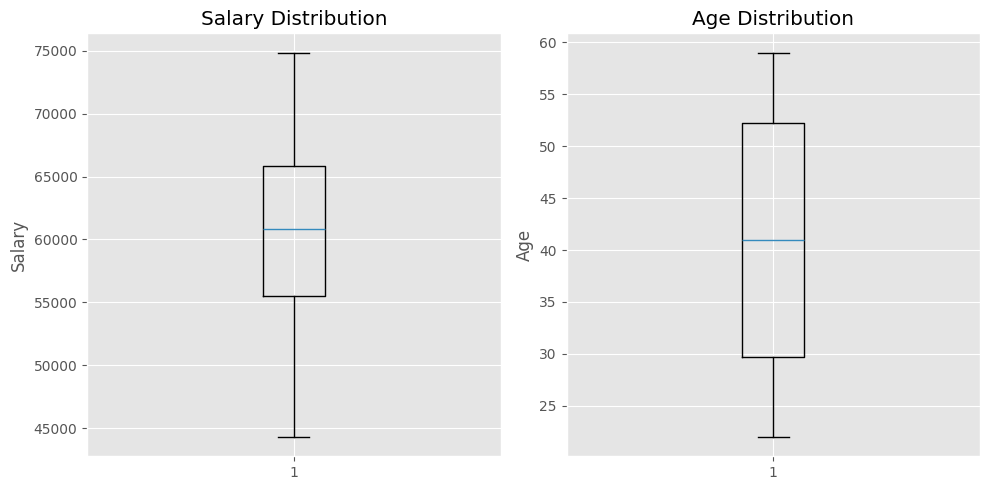

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Salary
axes[0].boxplot(analysis_simple["Salary"])
axes[0].set_ylabel("Salary")
axes[0].set_title("Salary Distribution")

# Age
axes[1].boxplot(analysis_simple["Age"])
axes[1].set_ylabel("Age")
axes[1].set_title("Age Distribution")

plt.tight_layout()
plt.show()

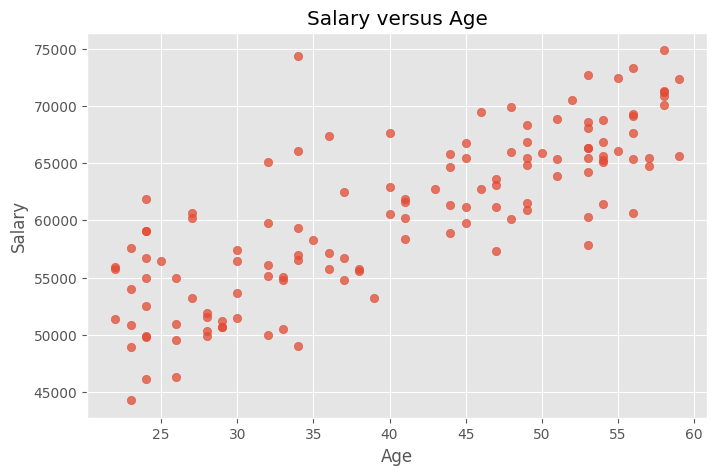

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(analysis_simple["Age"],
            analysis_simple["Salary"],
            alpha=0.75)

plt.xlabel("Age")
plt.ylabel("Salary")
plt.title("Salary versus Age")
plt.show()

### What should you look for in the scatterplot?

Before fitting a straight line, ask:

- Is there an upward or downward tendency?
- Is a straight-line description at least plausible?
- Are there unusual observations?
- Does the vertical spread appear similar across the range of age?
- Is the available age range wide enough to support the question?

A visual relationship is evidence of **association**, not necessarily causation.

> **Causation warning:** Even if salary and age are strongly associated, this notebook alone cannot establish that becoming one year older *causes* salary to increase by the regression slope. Other variables, selection mechanisms, and the study design matter.

## 3. First model: Salary explained by Age

Our first model is

$
Salary_i = \beta_0+\beta_1Age_i+\varepsilon_i.
$

After fitting the sample data, we estimate

$
\widehat{Salary}=b_0+b_1Age.
$

### Meaning of the coefficients

- \(b_0\), the **intercept**, is the predicted salary when Age = 0.
- \(b_1\), the **slope**, is the estimated change in predicted salary associated with a one-unit increase in Age.

The intercept is mathematically necessary in many models but may have little practical meaning if Age = 0 is outside the relevant population.

> **Teacher prompt:** Ask students which coefficient describes the *change* in salary. Do not introduce p-values yet.

In [7]:
model_age = smf.ols("Salary ~ Age", data=analysis_simple).fit()

b0 = model_age.params["Intercept"]
b1 = model_age.params["Age"]

print(f"Intercept b0 = {b0:.3f}")
print(f"Age slope b1 = {b1:.3f}")
print()
print(f"Fitted equation: Salary_hat = {b0:.3f} + ({b1:.3f}) × Age")

Intercept b0 = 41324.850
Age slope b1 = 474.883

Fitted equation: Salary_hat = 41324.850 + (474.883) × Age


### Interpret the slope correctly

A strong template is:

> **For each additional year of age, the model predicts an average salary difference of \(b_1\) units.**

If \(b_1>0\), predicted salary increases as age increases.  
If \(b_1<0\), predicted salary decreases as age increases.

Avoid saying:

> “Every person receives exactly \(b_1\) more salary when they become one year older.”

That would turn an estimated cross-sectional association into an individual causal statement.

## 4. Prediction: let the equation do useful work

In [8]:
ages_to_predict = pd.DataFrame({"Age": [25, 35, 45]})

ages_to_predict["Predicted_Salary"] = model_age.predict(ages_to_predict)

ages_to_predict

,Age,Predicted_Salary
0,25,53196.928
1,35,57945.759
2,45,62694.590


### Guided lab 2 — Calculate one prediction manually

For an employee aged 35:

\[
\widehat{Salary}=b_0+b_1(35)
\]

Use the coefficients printed above and calculate the result yourself. Then compare it with Python.

> **Prediction vs. truth:** A fitted value is not a guarantee of the person's actual salary. It is the model's estimate of the conditional mean salary at that predictor value.

> **Extrapolation warning:** Predicting far outside the observed age range is risky. A regression line is not a license to assume the same relationship continues indefinitely.

In [9]:
age_value = 35
manual_prediction = b0 + b1 * age_value
python_prediction = model_age.predict(pd.DataFrame({"Age": [age_value]})).iloc[0]

print(f"Manual prediction: {manual_prediction:.3f}")
print(f"Python prediction: {python_prediction:.3f}")

Manual prediction: 57945.759
Python prediction: 57945.759


## 5. Fitted values and residuals: the heart of regression

For observation \(i\):

\[
e_i = y_i-\hat y_i
\]

where:

- \(y_i\) = observed salary,
- \(\hat y_i\) = fitted/predicted salary,
- \(e_i\) = residual.

Interpretation:

- residual \(>0\): actual salary is above the fitted line;
- residual \(<0\): actual salary is below the fitted line;
- residual \(=0\): the fitted value equals the observed value.

Ordinary least squares chooses coefficients that minimize

\[
\sum_{i=1}^{n} e_i^2.
\]

That is why it is called **least squares**.

,Salary,Age,Predicted_Salary,Residual
0,74862.0,58.0,68868.071,5993.929
1,60652.0,56.0,67918.305,-7266.305
2,65058.0,54.0,66968.538,-1910.538
3,46284.0,26.0,53671.811,-7387.811
4,60945.0,49.0,64594.123,-3649.123
5,51910.0,28.0,54621.577,-2711.577
7,50704.0,29.0,55096.460,-4392.460
8,50506.0,33.0,56995.993,-6489.993
9,66032.0,55.0,67443.421,-1411.421
10,68807.0,54.0,66968.538,1838.462


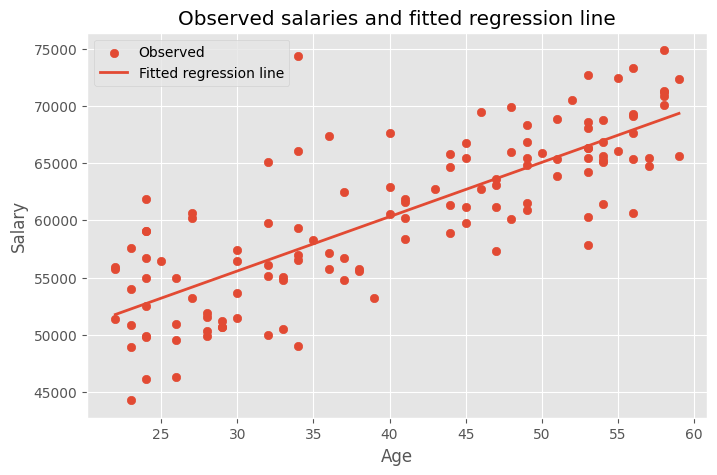

In [10]:
simple_results = analysis_simple.copy()
simple_results["Predicted_Salary"] = model_age.fittedvalues
simple_results["Residual"] = model_age.resid

display(simple_results.head(10))

plt.figure(figsize=(8, 5))
plt.scatter(simple_results["Age"], simple_results["Salary"], label="Observed")
order = np.argsort(simple_results["Age"].to_numpy())
plt.plot(
    simple_results["Age"].to_numpy()[order],
    simple_results["Predicted_Salary"].to_numpy()[order],
    linewidth=2,
    label="Fitted regression line"
)
plt.xlabel("Age")
plt.ylabel("Salary")
plt.title("Observed salaries and fitted regression line")
plt.legend()
plt.show()

### Your turn — residual reasoning

Suppose an employee's actual salary is 2,100 and the model predicts 2,000.

\[
e=2100-2000=100
\]

The residual is **+100**, meaning the employee earns 100 units more than the model predicted.

If you accidentally calculate `predicted − actual`, you reverse the sign.

> **Teacher note:** Residuals are worth slowing down for. They connect the regression equation to model diagnostics later in the notebook.

## 6. How much does the model explain? \(R^2\)

In [11]:
print(f"R-squared = {model_age.rsquared:.3f}")

R-squared = 0.636


The coefficient of determination is

\[
R^2 = 1-\frac{\text{unexplained variation}}{\text{total variation}}.
\]

For an OLS model with an intercept, \(R^2\) is usually between 0 and 1.

A useful interpretation is:

> **\(R^2\) is the proportion of observed variation in the response that is accounted for by the fitted model, in this sample.**

For example, \(R^2=0.60\) means the model accounts for about 60% of the observed variation in salary.

### What \(R^2\) does NOT mean

It does not mean:

- the model is “60% correct”;
- age causes 60% of salary;
- 60% of employees are predicted correctly;
- a high-\(R^2\) model is automatically scientifically appropriate.

Prediction quality should ideally be evaluated on new/held-out data when prediction is the goal.

## 7. Statistical inference: reading an OLS summary without fear

In [12]:
model_age.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.636
Model:                            OLS   Adj. R-squared:                  0.634
Method:                 Least Squares   F-statistic:                     220.6
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           1.82e-29
Time:                        21:34:36   Log-Likelihood:                -1250.0
No. Observations:                 128   AIC:                             2504.
Df Residuals:                     126   BIC:                             2510.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4.132e+04   1348.047     30.655      0.000    3.87e+04     4.4e+04
Age          474.8831     31.973     14.853      0.000     411.610     538.156
==============================================================================
Omnibus:                       10.694   Durbin-Watson:                   1.811
Prob(Omnibus):                  0.005   Jarque-Bera (JB):               11.906
Skew:                           0.559   Prob(JB):                      0.00260
Kurtosis:                       3.992   Cond. No.                         151.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The summary contains much more information than a beginner needs at once. Start with these items:

| Output | Question it helps answer |
|---|---|
| `coef` | What effect/association did the model estimate? |
| `std err` | How uncertain is the coefficient estimate? |
| `t` | How large is the estimate relative to its standard error? |
| `P>|t|` | Under the null hypothesis, how surprising is an estimate this extreme? |
| `[0.025, 0.975]` | What is the approximate 95% confidence interval? |
| `R-squared` | How much sample variation is accounted for by the model? |
| `Adj. R-squared` | \(R^2\) adjusted for model size |

### A careful interpretation of a p-value

For the Age coefficient, the conventional null hypothesis is

\[
H_0:\beta_{Age}=0.
\]

A small p-value means the observed estimate would be relatively unusual under the model assumptions if the true coefficient were zero.

It **does not** tell us:

- the probability that the null hypothesis is true;
- the probability that our model is correct;
- whether the effect is practically important;
- whether the relationship is causal.

### Confidence interval

A confidence interval communicates both **effect size** and **uncertainty**. In many applications, it is more informative than reporting only “significant/not significant.”

> **Teacher note:** Introduce the remaining diagnostics in the summary only when the course is ready for them. `Df Model` is the number of estimated slope terms represented by the model design (subject to rank), **not** “the number of pieces of information needed to predict salary.”

## 8. Degrees of freedom — correcting a common misconception

In an ordinary full-rank regression with \(n\) observations and \(p\) estimated parameters **including the intercept**,

\[
df_{resid}=n-p.
\]

For the simple model `Salary ~ Age`, there are typically two estimated parameters:

1. the intercept;
2. the Age coefficient.

So residual degrees of freedom are approximately \(n-2\).

`Df Model` in `statsmodels` is related to the number of model terms beyond the intercept. It is **not** a statement such as:

> “Df Model = 2, therefore we need two pieces of personal information to predict salary.”

Prediction inputs are determined by the predictors in the fitted formula, while degrees of freedom are statistical quantities related to model estimation and uncertainty.

## 9. Diagnose the simple model

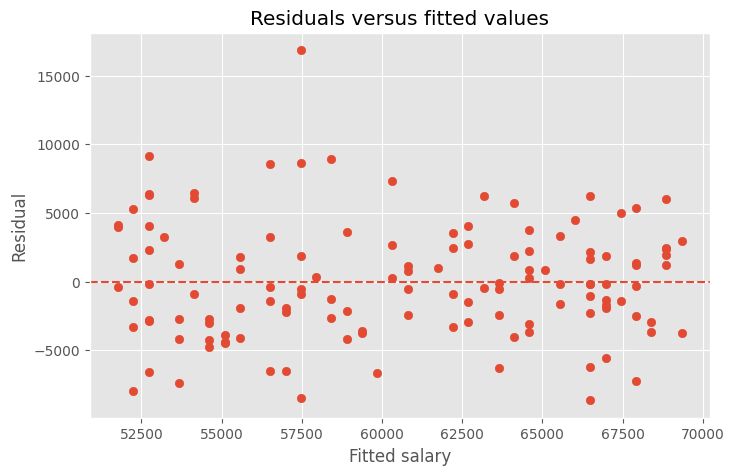

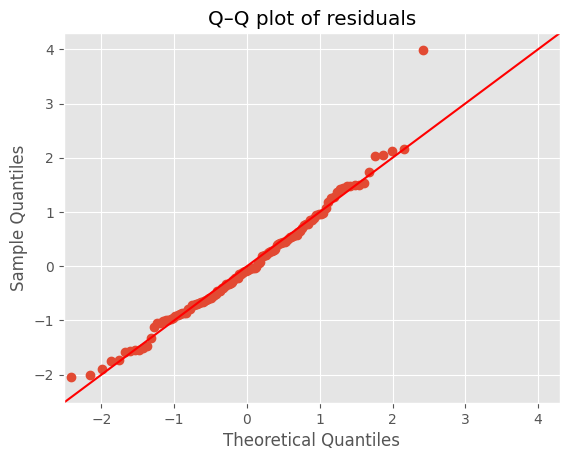

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(model_age.fittedvalues, model_age.resid)
plt.axhline(0, linestyle="--")
plt.xlabel("Fitted salary")
plt.ylabel("Residual")
plt.title("Residuals versus fitted values")
plt.show()

sm_qq = __import__("statsmodels.api", fromlist=["qqplot"])
sm_qq.qqplot(model_age.resid, line="45", fit=True)
plt.title("Q–Q plot of residuals")
plt.show()

### Four core ideas behind the classical linear model

For introductory work, think of the assumptions as questions:

1. **Linearity:** Is the mean relationship adequately represented by the model form?
2. **Independence:** Are observations/errors reasonably independent?
3. **Constant variance (homoscedasticity):** Is residual spread roughly stable across fitted values?
4. **Normality of errors:** Are residuals approximately normal when normal-theory inference is being used, especially in small samples?

The residual-vs-fitted plot is useful for spotting curvature and changing variance.  
The Q–Q plot helps assess whether residuals depart strongly from a normal distribution.

### Important nuance

Normality is **not** required merely to compute OLS coefficients. It is part of the traditional finite-sample inference framework. With large samples, asymptotic methods may reduce dependence on exact normality, but other problems—such as dependence or heteroscedasticity—still matter.

> **Common mistake:** A diagnostic plot does not “prove” an assumption. It provides evidence about whether a model seems reasonable.

## 10. Adding a categorical predictor: Gender

Now the manager asks:

> **“After accounting for age, is there an estimated salary difference between gender categories?”**

A categorical predictor cannot be interpreted as an ordinary numerical scale. Formula-based regression creates **indicator variables**.

If `Female` is the reference category, conceptually:

$$
Male_i =
\begin{cases}
1 & \text{if employee }i\text{ is Male}\\
0 & \text{if employee }i\text{ is Female}
\end{cases}
$$

The model becomes

$$
Salary_i=\beta_0+\beta_1Age_i+\beta_2Male_i+\varepsilon_i.
$$

Then:

**Female**
$$
\widehat{Salary}=\beta_0+\beta_1Age
$$

**Male**
$$
\widehat{Salary}=\beta_0+\beta_1Age+\beta_2
$$

So $\beta_2$ represents an adjusted difference between the two category-specific intercepts when no Age×Gender interaction is included.

In [14]:
analysis_gender = df[["Salary", "Age", "Gender"]].dropna().copy()
print(analysis_gender["Gender"].value_counts())

model_gender = smf.ols("Salary ~ Age + C(Gender)", data=analysis_gender).fit()
model_gender.summary()

Gender
Female    63
Male      53
Name: count, dtype: int64


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.634
Model:                            OLS   Adj. R-squared:                  0.627
Method:                 Least Squares   F-statistic:                     97.77
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           2.25e-25
Time:                        21:34:37   Log-Likelihood:                -1130.2
No. Observations:                 116   AIC:                             2266.
Df Residuals:                     113   BIC:                             2275.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          4.207e+04   1463.812     28.738      0.000    3.92e+04     4.5e+04
C(Gender)[T.Male]  -169.8422    780.710     -0.218      0.828   -1716.570    1376.886
Age                 457.3352     32.846     13.924      0.000     392.261     522.409
==============================================================================
Omnibus:                       11.349   Durbin-Watson:                   1.735
Prob(Omnibus):                  0.003   Jarque-Bera (JB):               13.893
Skew:                           0.563   Prob(JB):                     0.000962
Kurtosis:                       4.268   Cond. No.                         163.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### How to identify the reference category

Look at the coefficient names. If the output contains something like:

`C(Gender)[T.Male]`

then `Male` is being compared with the category that does **not** receive its own displayed coefficient. That omitted category is the **reference category**.

The exact reference depends on category coding/order unless you explicitly set it.

### Correct interpretation template

> **Holding age constant**, the estimated mean salary for the displayed gender category differs from the reference category by the corresponding coefficient.

Notice the phrase **holding age constant**. This is essential in multiple regression.

> **Fairness/ethics note:** A coefficient describing a group difference is descriptive/model-based evidence. It does not by itself explain why the difference exists, establish discrimination, or justify using a protected characteristic for consequential decisions.

In [15]:
print(model_gender.params)

# Example: model-based predictions for employees of the same age
gender_levels = analysis_gender["Gender"].dropna().unique().tolist()
example_people = pd.DataFrame({
    "Age": [35] * len(gender_levels),
    "Gender": gender_levels
})
example_people["Predicted_Salary"] = model_gender.predict(example_people)
example_people

Intercept            42067.442
C(Gender)[T.Male]     -169.842
Age                    457.335
dtype: float64


,Age,Gender,Predicted_Salary
0,35,Male,57904.331
1,35,Female,58074.173


## 11. Multiple regression: Age + Gender + Education

Now we ask a richer question:

> **“How are age, gender, and education associated with salary when considered together?”**

A multiple regression may be written conceptually as

\[
Salary=\beta_0+\beta_1Age+\text{Gender indicators}+\text{Education indicators}+\varepsilon.
\]

For a categorical variable with \(k\) categories, a model with an intercept typically uses \(k-1\) indicator coefficients. The omitted category becomes the reference.

This avoids perfect redundancy among the indicator variables and the intercept.

In [16]:
analysis_multi = df[["Salary", "Age", "Gender", "Education"]].dropna().copy()

print("Gender levels:")
print(analysis_multi["Gender"].value_counts())
print("\nEducation levels:")
print(analysis_multi["Education"].value_counts())

model_multi = smf.ols(
    "Salary ~ Age + C(Gender) + C(Education)",
    data=analysis_multi
).fit()

model_multi.summary()

Gender levels:
Gender
Female    56
Male      48
Name: count, dtype: int64

Education levels:
Education
PhD         40
Master      38
Bachelor    26
Name: count, dtype: int64


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.634
Model:                            OLS   Adj. R-squared:                  0.619
Method:                 Least Squares   F-statistic:                     42.85
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           8.13e-21
Time:                        21:34:37   Log-Likelihood:                -1012.1
No. Observations:                 104   AIC:                             2034.
Df Residuals:                      99   BIC:                             2048.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept               4.065e+04   1794.738     22.648      0.000    3.71e+04    4.42e+04
C(Gender)[T.Male]        -82.3865    828.094     -0.099      0.921   -1725.505    1560.732
C(Education)[T.Master]  2453.0811   1071.607      2.289      0.024     326.780    4579.382
C(Education)[T.PhD]      830.4541   1055.674      0.787      0.433   -1264.233    2925.141
Age                      462.6230     35.506     13.029      0.000     392.171     533.075
==============================================================================
Omnibus:                        5.702   Durbin-Watson:                   1.640
Prob(Omnibus):                  0.058   Jarque-Bera (JB):                5.448
Skew:                           0.400   Prob(JB):                       0.0656
Kurtosis:                       3.786   Cond. No.                         207.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### How to read this model

Use a disciplined order:

**1. Identify the reference categories.**  
They are the categories omitted from the coefficient list.

**2. Interpret Age.**  
The Age coefficient is the estimated salary difference associated with one additional year of age, **holding Gender and Education constant**.

**3. Interpret a Gender coefficient.**  
It compares that gender category with the gender reference category, **holding Age and Education constant**.

**4. Interpret an Education coefficient.**  
It compares that education category with the education reference category, **holding Age and Gender constant**.

### The intercept

The intercept corresponds to the predicted salary for someone:

- with Age = 0,
- in the reference Gender category,
- in the reference Education category.

That combination may be unrealistic. Therefore, the intercept may be mathematically useful without being substantively interesting.

### Guided lab 3 — Predict profiles, not hand-coded equations

In [17]:
print("Estimated coefficients:")
display(model_multi.params.to_frame("coefficient"))

# Build valid profiles from observed category labels.
g0 = analysis_multi["Gender"].iloc[0]
e0 = analysis_multi["Education"].iloc[0]

profiles = pd.DataFrame({
    "Age": [30, 40],
    "Gender": [g0, g0],
    "Education": [e0, e0]
})
profiles["Predicted_Salary"] = model_multi.predict(profiles)
profiles

Estimated coefficients:


,coefficient
Intercept,40647.384
C(Gender)[T.Male],-82.387
C(Education)[T.Master],2453.081
C(Education)[T.PhD],830.454
Age,462.623


,Age,Gender,Education,Predicted_Salary
0,30,Male,Master,56896.769
1,40,Male,Master,61522.999


Using `model.predict()` is safer than copying coefficients manually into a long arithmetic expression. It reduces errors when reference categories or model specifications change.

> **Teacher note:** The original notebook used manually typed coefficients in several case studies. That is useful for one demonstration of the algebra, but it is fragile as a general workflow. Have students do one prediction by hand, then use `predict()` thereafter.

## 12. A subtle modeling decision: JoinYear

`JoinYear` creates an excellent conceptual lesson.

### Option A — Treat year as numerical

$$
Salary=\beta_0+\beta_1JoinYear+\varepsilon
$$

This assumes a **linear change per one-year increase** in joining year.

### Option B — Treat year as categorical

$$
Salary=\beta_0+\text{year indicators}+\varepsilon
$$

This makes separate comparisons between years and a reference year, without assuming equal year-to-year change.

Neither coding is automatically “correct.” The correct choice depends on the scientific/business question and whether the assumed functional form is reasonable.

> “Does the difference between 2004 and 2005 have the same modeled meaning as the difference between 2009 and 2010?” If yes, numerical coding may make sense. If not, categorical coding may be preferable.

In [18]:
analysis_year = df[["Salary", "JoinYear"]].dropna().copy()

model_year_numeric = smf.ols("Salary ~ JoinYear", data=analysis_year).fit()
model_year_category = smf.ols("Salary ~ C(JoinYear)", data=analysis_year).fit()

comparison = pd.DataFrame({
    "Model": ["JoinYear numerical", "JoinYear categorical"],
    "R_squared": [model_year_numeric.rsquared, model_year_category.rsquared],
    "Adjusted_R_squared": [model_year_numeric.rsquared_adj, model_year_category.rsquared_adj],
    "Parameters": [len(model_year_numeric.params), len(model_year_category.params)]
})
comparison

,Model,R_squared,Adjusted_R_squared,Parameters
0,JoinYear numerical,0.058,0.050,2
1,JoinYear categorical,0.218,0.045,23


### Do not select a model using \(R^2\) alone

Adding parameters cannot reduce ordinary in-sample \(R^2\). A more flexible categorical model may therefore have a larger \(R^2\) even when the additional complexity is not useful.

Consider:

- the research question;
- interpretability;
- adjusted \(R^2\);
- uncertainty;
- diagnostics;
- and, for prediction, performance on data not used to fit the model.

## 13. Interactions: when one relationship depends on another variable

An interaction asks whether the effect/association of one predictor changes depending on another predictor.

For two categorical variables:

```text
Salary ~ Gender * Education
```

is shorthand for:

```text
Salary ~ Gender + Education + Gender:Education
```

So the model contains:

1. the main effect of Gender;
2. the main effect of Education;
3. Gender × Education interaction terms.

### Why interactions change interpretation

Once an interaction is included, a “main effect” is conditional on the other interacting variable being at its reference level.

Therefore, do **not** interpret the Gender coefficient as a universal gender difference when Gender interacts with Education.

In [19]:
analysis_interaction = df[["Salary", "Gender", "Education"]].dropna().copy()

model_interaction = smf.ols(
    "Salary ~ C(Gender) * C(Education)",
    data=analysis_interaction
).fit()

model_interaction.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.036
Model:                            OLS   Adj. R-squared:                 -0.011
Method:                 Least Squares   F-statistic:                    0.7717
Date:                Fri, 16 Oct 2026   Prob (F-statistic):              0.572
Time:                        21:34:37   Log-Likelihood:                -1122.5
No. Observations:                 110   AIC:                             2257.
Df Residuals:                     104   BIC:                             2273.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
============================================================================================================
                                               coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------
Intercept                                 5.995e+04   1735.844     34.535      0.000    5.65e+04    6.34e+04
C(Gender)[T.Male]                         1501.8667   2498.307      0.601      0.549   -3452.370    6456.103
C(Education)[T.Master]                    1155.9101   2231.201      0.518      0.606   -3268.645    5580.465
C(Education)[T.PhD]                       2686.2351   2322.060      1.157      0.250   -1918.497    7290.967
C(Gender)[T.Male]:C(Education)[T.Master] -1128.1879   3273.775     -0.345      0.731   -7620.206    5363.830
C(Gender)[T.Male]:C(Education)[T.PhD]    -5335.1875   3282.164     -1.626      0.107   -1.18e+04    1173.466
==============================================================================
Omnibus:                        4.989   Durbin-Watson:                   1.670
Prob(Omnibus):                  0.083   Jarque-Bera (JB):                2.675
Skew:                          -0.117   Prob(JB):                        0.262
Kurtosis:                       2.273   Cond. No.                         10.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### The easiest way to understand an interaction: predicted group means

Rather than trying to interpret every interaction coefficient in isolation, generate predictions for all combinations of the interacting categories.

In [20]:
gender_levels = sorted(analysis_interaction["Gender"].astype(str).unique())
education_levels = sorted(analysis_interaction["Education"].astype(str).unique())

grid = pd.DataFrame(
    [(g, e) for g in gender_levels for e in education_levels],
    columns=["Gender", "Education"]
)
grid["Predicted_Salary"] = model_interaction.predict(grid)
grid

,Gender,Education,Predicted_Salary
0,Female,Bachelor,59948.133
1,Female,Master,61104.043
2,Female,PhD,62634.368
3,Male,Bachelor,61450.000
4,Male,Master,61477.722
5,Male,PhD,58801.048


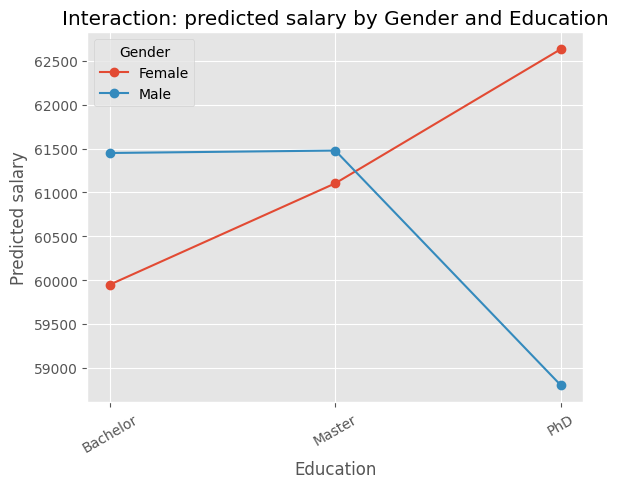

In [21]:
for gender, group in grid.groupby("Gender"):
    plt.plot(group["Education"], group["Predicted_Salary"], marker="o", label=gender)

plt.xlabel("Education")
plt.ylabel("Predicted salary")
plt.title("Interaction: predicted salary by Gender and Education")
plt.legend(title="Gender")
plt.xticks(rotation=30)
plt.show()

If the pattern of differences across education levels changes substantially by gender, the plot helps us see the interaction.

> **Important:** An interaction is not simply “two variables are significant together.” It means the modeled association involving one variable depends on the level/value of another.

## 14. Model diagnostics for multiple regression

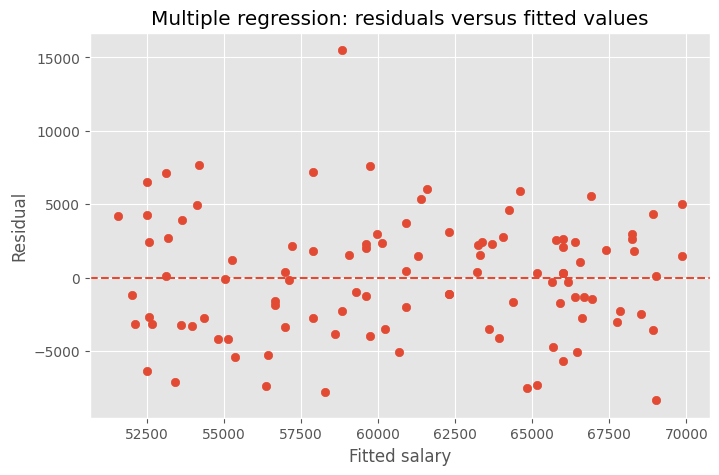

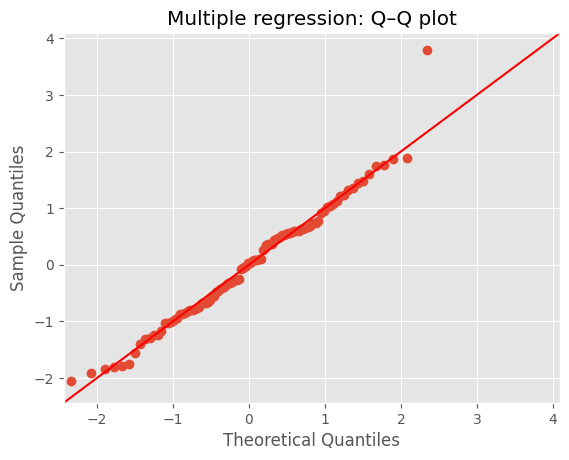

In [22]:
fig = plt.figure(figsize=(8, 5))
plt.scatter(model_multi.fittedvalues, model_multi.resid)
plt.axhline(0, linestyle="--")
plt.xlabel("Fitted salary")
plt.ylabel("Residual")
plt.title("Multiple regression: residuals versus fitted values")
plt.show()

import statsmodels.api as sm
sm.qqplot(model_multi.resid, line="45", fit=True)
plt.title("Multiple regression: Q–Q plot")
plt.show()

### What patterns should worry us?

**Curvature** in residuals  
→ the model may be missing nonlinear structure.

**Funnel shape**  
→ residual variance may not be constant.

**Extreme residuals**  
→ investigate unusual observations; do not automatically delete them.

**Strong Q–Q departures**  
→ normal-theory inference may need more care, particularly in small samples.

### Never delete an observation merely because it is inconvenient

An outlier can be:

- a data-entry error;
- a valid but unusual observation;
- evidence of a missing variable;
- evidence that the model form is inappropriate.

Investigate first. Document any exclusion rule.

## 15. Association, prediction, and causation are different goals

A professional regression analysis begins by deciding what the model is for.

### Association
**Question:** How is salary associated with age after accounting for education?

Coefficient interpretation is central.

### Prediction
**Question:** How accurately can we predict salary for a new employee?

Out-of-sample validation is central.

### Causation
**Question:** What would happen to salary if we intervened and changed a particular exposure?

Regression alone does not create causal identification. Study design, confounding, temporal ordering, selection, and causal assumptions become essential.

> **Teacher note:** This distinction prevents one of the most common beginner errors: turning every regression coefficient into a causal effect.

## 16. A professional regression workflow

Use this workflow whenever you build a regression model:

1. **State the question.** What are we trying to explain, predict, or compare?
2. **Define the response.**
3. **Identify predictor types.** Numerical? Categorical? Ordered?
4. **Inspect missingness and data quality.**
5. **Explore the variables graphically.**
6. **Choose a model form that matches the question.**
7. **Fit the model.**
8. **Write the fitted equation or describe its structure.**
9. **Interpret coefficients in context.**
10. **Quantify uncertainty.**
11. **Examine residuals and diagnostics.**
12. **Avoid extrapolation beyond the supported data range.**
13. **Separate association from causation.**
14. **For prediction, validate on unseen data.**
15. **Communicate limitations as clearly as results.**

## 17. Check your understanding

Try to answer these **before** revealing the answers below.

1. If the Age coefficient is 48, does every employee receive 48 more salary on their next birthday?
2. What does a negative residual mean?
3. Does \(R^2=0.70\) mean the model is 70% accurate?
4. Why is one category omitted when a categorical predictor is dummy-coded with an intercept?
5. In `Salary ~ Age + Gender`, what does “holding Age constant” mean when interpreting Gender?
6. Does a small p-value prove a large or important effect?
7. Does a high \(R^2\) prove causation?
8. Why can predicting salary for Age = 5 be problematic if employees in the dataset are adults?
9. What does an interaction mean?
10. What is wrong with saying “Df Model = 4 means four pieces of information are required to predict salary”?

<details>
<summary><b>Click to reveal suggested answers</b></summary>

1. No. The coefficient is an estimated average association in the fitted model.
2. Actual salary is below the model's fitted value.
3. No. It describes explained sample variation, not percentage prediction accuracy.
4. To avoid perfect redundancy/collinearity with the intercept; the omitted level becomes the reference.
5. Compare gender categories at the same modeled age.
6. No. Statistical evidence and practical magnitude are different concepts.
7. No.
8. It is extrapolation outside the relevant observed predictor range.
9. The modeled relationship involving one predictor depends on another predictor's value/category.
10. Degrees of freedom concern model estimation; prediction inputs are determined by the predictors in the model.

</details>

## 18. Compact code template for future analyses

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.634
Model:                            OLS   Adj. R-squared:                  0.619
Method:                 Least Squares   F-statistic:                     42.85
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           8.13e-21
Time:                        21:34:39   Log-Likelihood:                -1012.1
No. Observations:                 104   AIC:                             2034.
Df Residuals:                      99   BIC:                             2048.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept               4.06

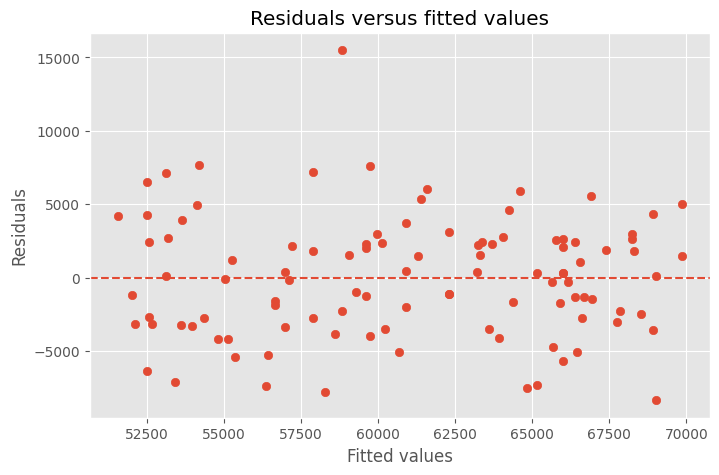

In [23]:
# 1. Select variables and remove rows missing values needed for this model.
analysis = df[["Salary", "Age", "Gender", "Education"]].dropna().copy()

# 2. Fit a model.
model = smf.ols(
    "Salary ~ Age + C(Gender) + C(Education)",
    data=analysis
).fit()

# 3. Inspect estimates and uncertainty.
print(model.summary())

# 4. Create fitted values and residuals.
analysis["Fitted"] = model.fittedvalues
analysis["Residual"] = model.resid

# 5. Diagnostic plot.
plt.figure(figsize=(8, 5))
plt.scatter(analysis["Fitted"], analysis["Residual"])
plt.axhline(0, linestyle="--")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals versus fitted values")
plt.show()

# 6. Make predictions using a DataFrame with the same predictor names.
# new_people = pd.DataFrame({
#     "Age": [...],
#     "Gender": [...],
#     "Education": [...]
# })
# model.predict(new_people)

# Final takeaway



Linear regression is not mainly about obtaining a line or pressing `fit()`.

A good regression analysis connects five things:

$$
\boxed{\text{Question} \rightarrow \text{Data} \rightarrow \text{Model} \rightarrow \text{Diagnostics} \rightarrow \text{Interpretation}}
$$

If any link is weak, a technically correct piece of Python can still produce a poor analysis.

The most important habit is therefore:

> **Never report a coefficient until you can explain—in words—what comparison or change that coefficient represents.**